# Análisis de la Brecha Digital en el Perú (Capa Gold)

Este notebook consume directamente el dataset analítico consolidado en la **Capa Gold** (`data/gold/brecha_digital_osiptel.parquet`).

### Principio Arquitectural de Big Data:
El notebook **no realiza ingesta, descargas ni limpiezas pesadas**. Toda la preparación y estandarización de datos (Raw y Silver) fue procesada de manera desacoplada por el orquestador `python run_pipeline.py`.

### Objetivos Analíticos:
1. Cargar el dataset final de la capa Gold (`data/gold/brecha_digital_osiptel.parquet`).
2. Calcular KPIs macro a nivel nacional (volumen de conexiones fijas y penetración de fibra óptica).
3. Analizar la evolución histórica trimestral y la transición tecnológica (Fibra vs. Cablemódem).
4. Evaluar la brecha digital departamental y la correlación con la competencia de operadoras.
5. Formular conclusiones ejecutivas basadas en evidencia para la toma de decisiones regulatorias.

In [1]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo visual para gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)

# 1. Cargar únicamente la capa Gold ya procesada por el pipeline
RUTAS_GOLD = [
    Path("../data/gold/brecha_digital_osiptel.parquet"),
    Path("data/gold/brecha_digital_osiptel.parquet"),
    Path("../data/gold/brecha_digital_consolidada.parquet"),
    Path("data/gold/brecha_digital_consolidada.parquet")
]

ruta_gold = next((p for p in RUTAS_GOLD if p.exists()), Path("../data/gold/brecha_digital_osiptel.parquet"))

try:
    df_gold = pd.read_parquet(ruta_gold)
    print(f"✅ Capa Gold cargada exitosamente desde: {ruta_gold}")
    print(f"Dimensiones analíticas: {df_gold.shape[0]} registros × {df_gold.shape[1]} columnas")
except Exception as e:
    print(f"⚠️ Archivo no encontrado en {ruta_gold}. Ejecuta primero: python run_pipeline.py")
    raise e

# 2. Vista preliminar de la capa analítica Gold
display(df_gold.head())

✅ Capa Gold cargada exitosamente desde: ../data/gold/brecha_digital_osiptel.parquet
Dimensiones analíticas: 1177 registros × 15 columnas


,anio,trimestre,departamento,total_conexiones,conexiones_fibra_optica,conexiones_cablemodem,total_operadoras_activas,pct_fibra_optica,hogares_internet_pct,computadora_pct,estado_integracion,mandatos_normativos_osiptel,expedientes_distintos,reportes_supervision_osiptel,temas_supervisados_distintos
0,2012,4,LIMA Y CALLAO,931542,0,113132,11,0.0,NaN,NaN,CONSOLIDADO_TOTAL_MULTI_FUENTE,0,NaN,0,NaN
1,2012,4,OTRAS REGIONES,513844,0,37269,11,0.0,NaN,NaN,CONSOLIDADO_TOTAL_MULTI_FUENTE,0,NaN,0,NaN
2,2013,1,LIMA Y CALLAO,957349,0,121398,11,0.0,NaN,NaN,CONSOLIDADO_TOTAL_MULTI_FUENTE,0,NaN,2,2.0
3,2013,1,OTRAS REGIONES,536319,0,40361,11,0.0,NaN,NaN,CONSOLIDADO_TOTAL_MULTI_FUENTE,0,NaN,2,2.0
4,2013,2,LIMA Y CALLAO,988577,0,132461,11,0.0,NaN,NaN,CONSOLIDADO_TOTAL_MULTI_FUENTE,0,NaN,2,2.0


In [2]:
# ======================================================================
# EVIDENCIA SECCIÓN 3.3: AUDITORÍA DE LIMPIEZA Y CONSOLIDACIÓN CAPA GOLD
# ======================================================================
from pathlib import Path
import json
import pandas as pd

# 1. Resolver ruta base automáticamente (soporta ejecución desde notebooks/ o raíz)
base_dir = Path("..") if Path("../data").exists() else Path(".")
rep_path = base_dir / "evidence" / "reporte_conexiones.json"
gold_path = base_dir / "data" / "gold" / "brecha_digital_osiptel.parquet"

print("=== 1. AUDITORÍA DE CALIDAD Y LIMPIEZA (CAPA SILVER) ===")
with open(rep_path) as f:
    rep = json.load(f)
for k, v in rep.items():
    if k not in ["nulos_por_columna", "completitud_por_campo"]:
        print(f"  • {k:25}: {v:,}")

print("\n=== 2. MUESTRA CONSOLIDADA CAPA GOLD (CRUCE MULTIFUENTE) ===")
df_gold = pd.read_parquet(gold_path)
print(f"Total registros analíticos consolidados: {len(df_gold):,}\n")

cols = ["anio", "trimestre", "departamento", "total_conexiones", "pct_fibra_optica", "hogares_internet_pct", "mandatos_normativos_osiptel"]
df_muestra = df_gold[df_gold["anio"] == "2024"][cols].tail(6)
display(df_muestra)


=== 1. AUDITORÍA DE CALIDAD Y LIMPIEZA (CAPA SILVER) ===
  • filas_leidas             : 141,106
  • filas_rechazadas         : 201
  • filas_validas            : 138,419
  • duplicados_eliminados    : 2,486
  • conflictos_de_clave      : 1,264
  • atipicos_marcados        : 20,271

=== 2. MUESTRA CONSOLIDADA CAPA GOLD (CRUCE MULTIFUENTE) ===
Total registros analíticos consolidados: 1,177



,anio,trimestre,departamento,total_conexiones,pct_fibra_optica,hogares_internet_pct,mandatos_normativos_osiptel
1046,2024,4,PIURA,165637,79.14,58.4,17
1047,2024,4,PUNO,57950,78.47,58.4,17
1048,2024,4,SAN MARTIN,57297,91.94,58.4,17
1049,2024,4,TACNA,55193,70.65,58.4,17
1050,2024,4,TUMBES,41553,90.04,58.4,17
1051,2024,4,UCAYALI,64321,88.64,58.4,17


### 1. Estructura y Esquema del Dataset Gold

In [3]:
df_gold.info()
display(df_gold.describe().T[["mean", "std", "min", "50%", "max"]])

<class 'pandas.DataFrame'>
RangeIndex: 1177 entries, 0 to 1176
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   anio                          1177 non-null   str    
 1   trimestre                     1177 non-null   int64  
 2   departamento                  1177 non-null   str    
 3   total_conexiones              1177 non-null   int64  
 4   conexiones_fibra_optica       1177 non-null   int64  
 5   conexiones_cablemodem         1177 non-null   int64  
 6   total_operadoras_activas      1177 non-null   int64  
 7   pct_fibra_optica              1177 non-null   float64
 8   hogares_internet_pct          1042 non-null   float64
 9   computadora_pct               1042 non-null   float64
 10  estado_integracion            1177 non-null   str    
 11  mandatos_normativos_osiptel   1177 non-null   int64  
 12  expedientes_distintos         825 non-null    float64
 13  reportes_super

,mean,std,min,50%,max
trimestre,2.501274,1.138477,1.0,3.0,4.00
total_conexiones,122757.528462,318900.582338,1.0,38298.0,2131777.00
conexiones_fibra_optica,29257.476636,148206.204451,0.0,0.0,1770004.00
conexiones_cablemodem,50424.753611,162667.394715,0.0,7104.0,1260091.00
total_operadoras_activas,14.689040,8.252921,1.0,13.0,57.00
pct_fibra_optica,19.861818,33.440789,0.0,0.0,94.29
hogares_internet_pct,42.121305,12.637593,24.1,39.6,58.90
computadora_pct,36.456910,2.022523,31.8,36.4,41.30
mandatos_normativos_osiptel,10.598980,12.033920,0.0,9.0,45.00
expedientes_distintos,8.454545,5.644671,1.0,8.0,23.00


### 2. KPIs Macro a Nivel Nacional

Calculamos los indicadores de volumen y penetración en el periodo más reciente registrado.

In [4]:
max_anio = df_gold["anio"].astype(str).max()
ultimo_trim = df_gold[df_gold["anio"].astype(str) == max_anio]["trimestre"].max()

df_actual = df_gold[(df_gold["anio"].astype(str) == max_anio) & (df_gold["trimestre"] == ultimo_trim)]

total_conexiones = df_actual["total_conexiones"].sum()
total_fibra = df_actual["conexiones_fibra_optica"].sum()
pct_fibra = (total_fibra / total_conexiones) * 100 if total_conexiones > 0 else 0

print(f"=== INDICADORES NACIONALES ({max_anio} - Trimestre {ultimo_trim}) ===")
print(f"• Total Conexiones Fijas:       {total_conexiones:,.0f}")
print(f"• Conexiones en Fibra Óptica:   {total_fibra:,.0f}")
print(f"• Penetración de Fibra Óptica:  {pct_fibra:.2f}%")
print(f"• Departamentos Monitoreados:   {df_actual['departamento'].nunique()}")

=== INDICADORES NACIONALES (2026 - Trimestre 1) ===
• Total Conexiones Fijas:       4,135,995
• Conexiones en Fibra Óptica:   3,414,062
• Penetración de Fibra Óptica:  82.55%
• Departamentos Monitoreados:   25


### 3. Evolución Histórica Trimestral: Transición a Fibra Óptica

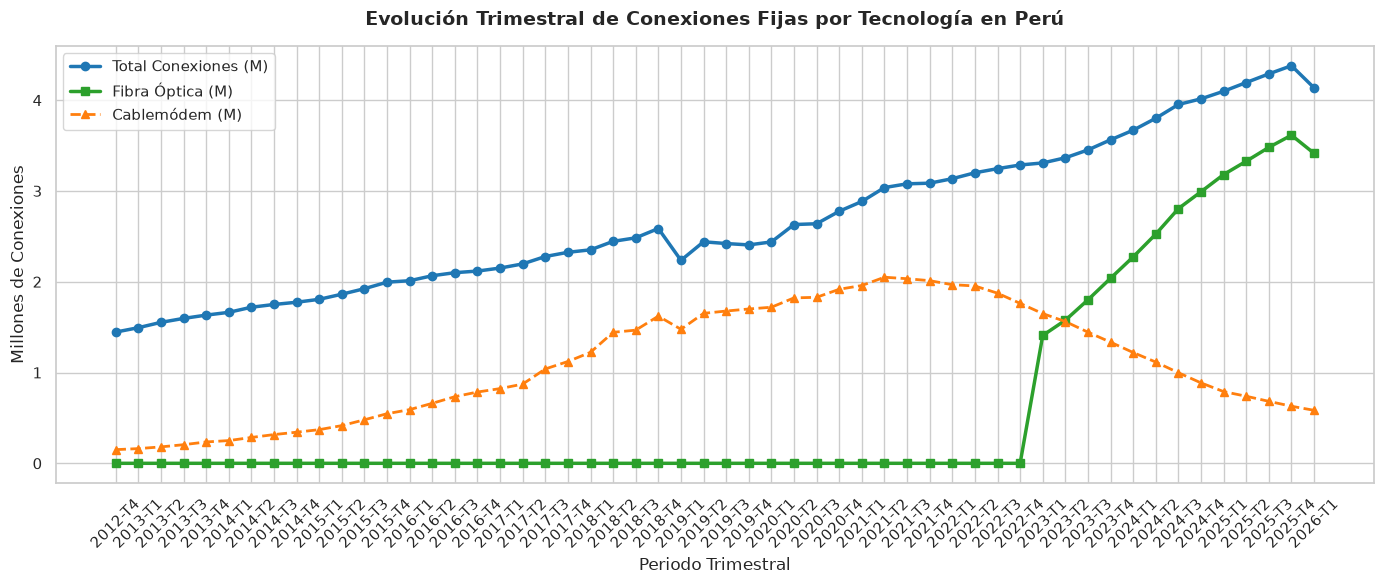

In [5]:
df_evol = df_gold.groupby(["anio", "trimestre"]).agg({
    "total_conexiones": "sum",
    "conexiones_fibra_optica": "sum",
    "conexiones_cablemodem": "sum"
}).reset_index()

df_evol["periodo_label"] = df_evol["anio"].astype(str) + "-T" + df_evol["trimestre"].astype(str)
df_evol = df_evol.sort_values(by=["anio", "trimestre"])

plt.figure(figsize=(14, 6))
plt.plot(df_evol["periodo_label"], df_evol["total_conexiones"] / 1e6, marker="o", linewidth=2.5, label="Total Conexiones (M)", color="#1f77b4")
plt.plot(df_evol["periodo_label"], df_evol["conexiones_fibra_optica"] / 1e6, marker="s", linewidth=2.5, label="Fibra Óptica (M)", color="#2ca02c")
plt.plot(df_evol["periodo_label"], df_evol["conexiones_cablemodem"] / 1e6, marker="^", linewidth=2, linestyle="--", label="Cablemódem (M)", color="#ff7f0e")

plt.title("Evolución Trimestral de Conexiones Fijas por Tecnología en Perú", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Periodo Trimestral", fontsize=12)
plt.ylabel("Millones de Conexiones", fontsize=12)
plt.xticks(rotation=45)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

### 4. Brecha Digital Departamental (Ranking Territorial)

/tmp/ipykernel_10244/1136646456.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ranking_dept, x="total_conexiones", y="departamento", palette="viridis")


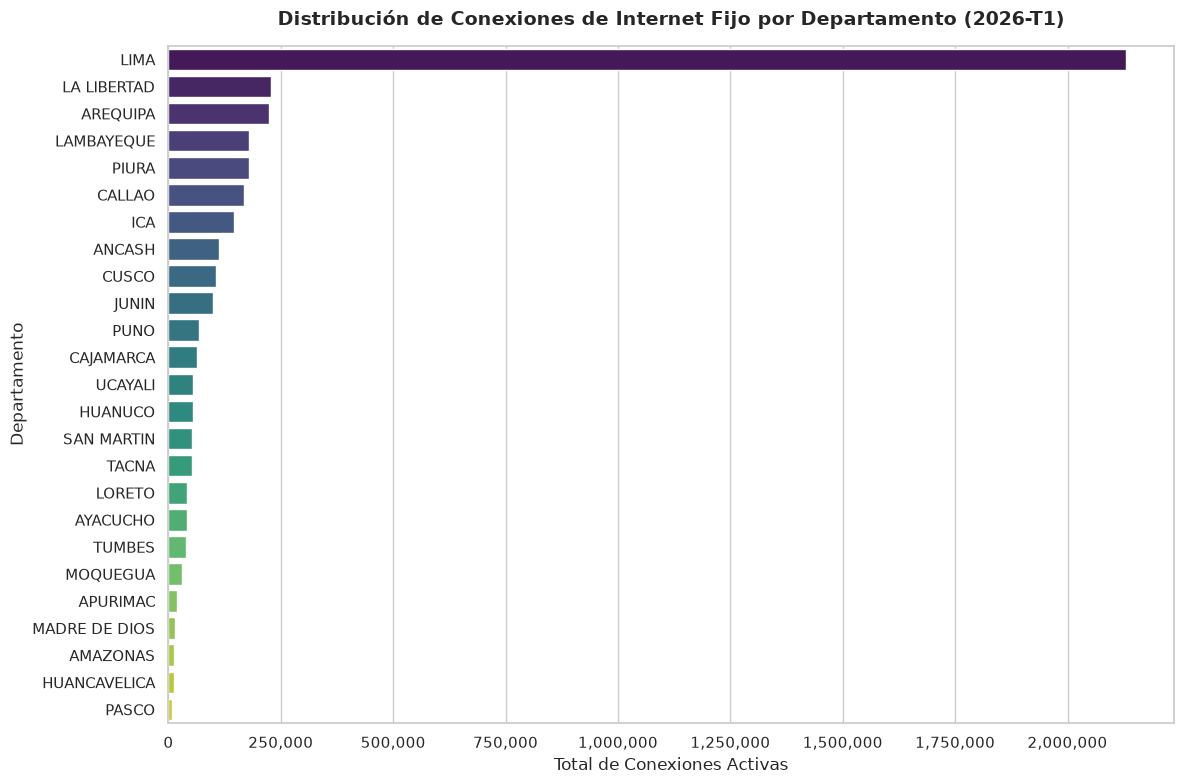

In [6]:
ranking_dept = df_actual.groupby("departamento").agg({
    "total_conexiones": "sum",
    "conexiones_fibra_optica": "sum",
    "total_operadoras_activas": "mean"
}).reset_index()

ranking_dept["pct_fibra"] = (ranking_dept["conexiones_fibra_optica"] / ranking_dept["total_conexiones"]) * 100
ranking_dept = ranking_dept.sort_values(by="total_conexiones", ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(data=ranking_dept, x="total_conexiones", y="departamento", palette="viridis")
plt.title(f"Distribución de Conexiones de Internet Fijo por Departamento ({max_anio}-T{ultimo_trim})", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Total de Conexiones Activas", fontsize=12)
plt.ylabel("Departamento", fontsize=12)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{int(x):,}"))
plt.tight_layout()
plt.show()

### 5. Competencia de Mercado y Penetración de Fibra Óptica

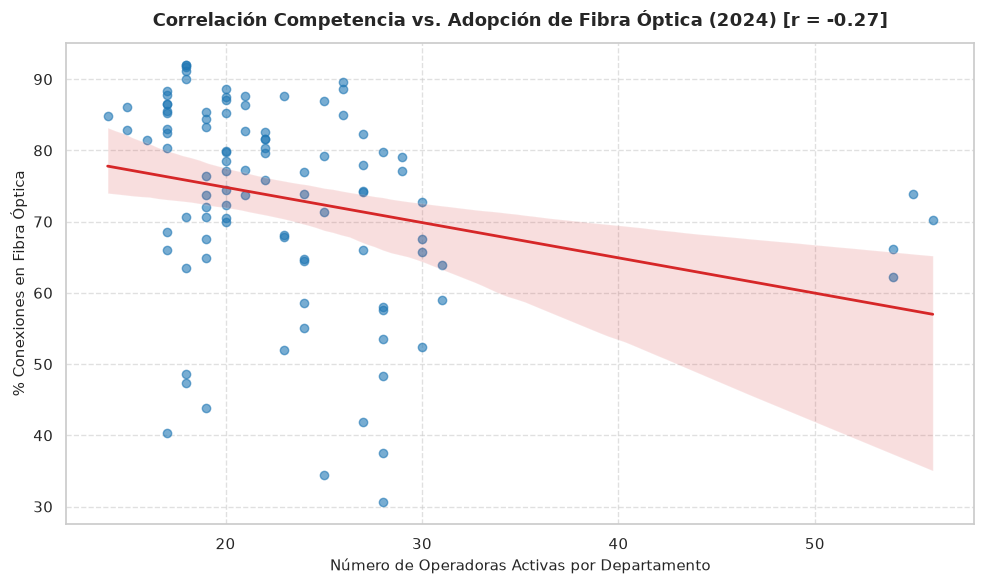

• Correlación de Pearson (Competencia vs % Fibra 2024): -0.2726


In [7]:
# Análisis de correlación entre operadores activos y penetración de fibra
plt.figure(figsize=(10, 6))
sns.regplot(
    data=df_gold[df_gold["anio"] == "2024"],
    x="total_operadoras_activas",
    y="pct_fibra_optica",
    scatter_kws={"alpha": 0.6, "color": "#1f77b4"},
    line_kws={"color": "#d62728", "linewidth": 2}
)
corr_val = df_gold[df_gold["anio"] == "2024"]["total_operadoras_activas"].corr(df_gold[df_gold["anio"] == "2024"]["pct_fibra_optica"])
plt.title(f"Correlación Competencia vs. Adopción de Fibra Óptica (2024) [r = {corr_val:.2f}]", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Número de Operadoras Activas por Departamento", fontsize=11)
plt.ylabel("% Conexiones en Fibra Óptica", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()
print(f"• Correlación de Pearson (Competencia vs % Fibra 2024): {corr_val:.4f}")


### 6. Integración Multivariada: Conexiones Fijas (OSIPTEL) vs. Hogares con Internet (INEI)

Cruzamos la oferta de infraestructura de OSIPTEL con la demanda efectiva de los hogares reportada en la encuesta ENAHO del INEI (`hogares_internet_pct`).

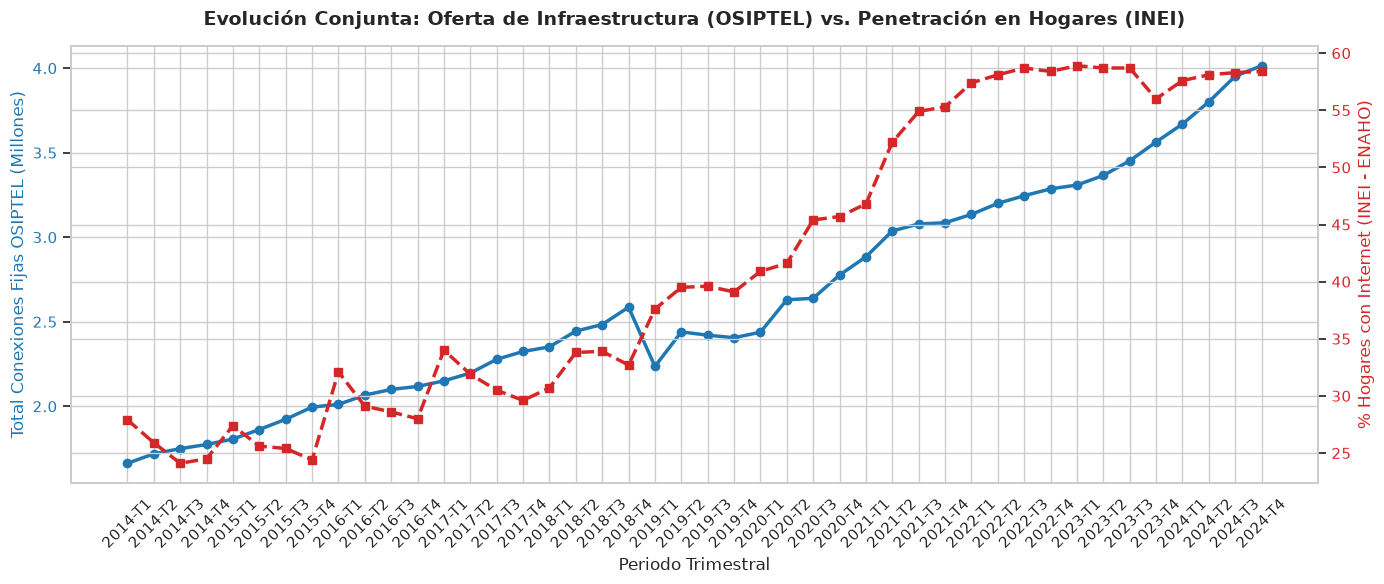

Correlación de Pearson entre Conexiones Fijas y % Hogares con Internet: 0.9458


In [8]:
# Filtrar registros donde existe coincidencia con la serie del INEI
df_cruce = df_gold[df_gold['hogares_internet_pct'].notna()].copy()

cruce_trim = df_cruce.groupby(['anio', 'trimestre']).agg({
    'total_conexiones': 'sum',
    'conexiones_fibra_optica': 'sum',
    'hogares_internet_pct': 'mean'
}).reset_index()

cruce_trim['periodo_label'] = cruce_trim['anio'].astype(str) + '-T' + cruce_trim['trimestre'].astype(str)
cruce_trim = cruce_trim.sort_values(by=['anio', 'trimestre'])

fig, ax1 = plt.subplots(figsize=(14, 6))

color = '#1f77b4'
ax1.set_xlabel('Periodo Trimestral', fontsize=12)
ax1.set_ylabel('Total Conexiones Fijas OSIPTEL (Millones)', color=color, fontsize=12)
ax1.plot(cruce_trim['periodo_label'], cruce_trim['total_conexiones'] / 1e6, color=color, marker='o', linewidth=2.5, label='Conexiones Fijas (OSIPTEL)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.tick_params(axis='x', rotation=45)

ax2 = ax1.twinx()
color = '#d62728'
ax2.set_ylabel('% Hogares con Internet (INEI - ENAHO)', color=color, fontsize=12)
ax2.plot(cruce_trim['periodo_label'], cruce_trim['hogares_internet_pct'], color=color, marker='s', linestyle='--', linewidth=2.5, label='% Hogares con Internet (INEI)')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Evolución Conjunta: Oferta de Infraestructura (OSIPTEL) vs. Penetración en Hogares (INEI)', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()

corr = cruce_trim['total_conexiones'].corr(cruce_trim['hogares_internet_pct'])
print(f'Correlación de Pearson entre Conexiones Fijas y % Hogares con Internet: {corr:.4f}')

### 7. Modelo Predictivo Base (Baseline Model) - Regresión de Línea Base

Para dar cumplimiento al **Criterio 5 de la Rúbrica de Evaluación Parcial**, entrenamos un modelo de regresión base que establece la **línea base predictiva** para estimar la tasa de adopción de fibra óptica (`pct_fibra_optica`) en función de:
- `anio_num`: Tendencia secular temporal.
- `trimestre`: Ciclicidad estacional.
- `total_operadoras_activas`: Índice de competencia de mercado regional.
- `total_conexiones`: Escala de la base instalada.

=== MÉTRICAS DEL MODELO BASE (BASELINE REGRESSION) ===
• R² (Coeficiente de Determinación): 0.5790 (57.90% de varianza explicada)
• MAE (Error Absoluto Medio):        17.41%
• RMSE (Raíz del Error Cuadrático):  20.81%

Ponderación de Coeficientes de Línea Base:
  - anio_num                 : +5.965735
  - trimestre                : +0.755881
  - total_operadoras_activas : +0.934633
  - total_conexiones         : -0.000011


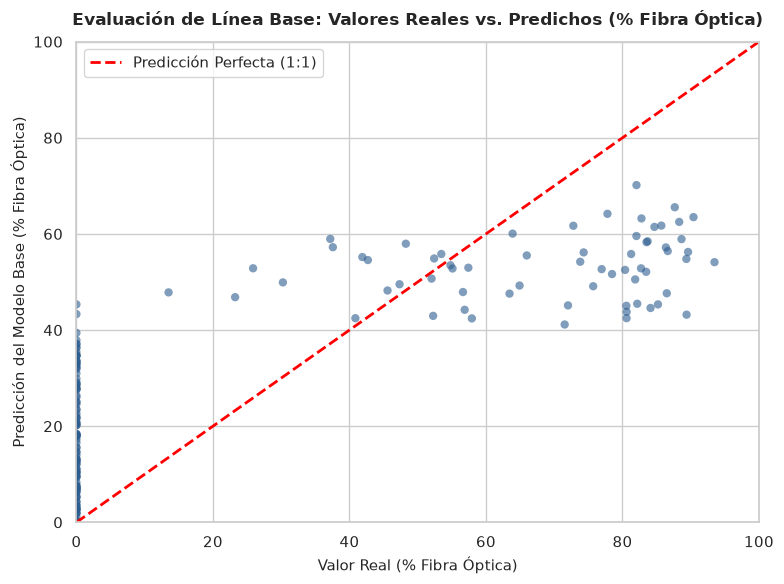

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split

# 1. Preparación de datos para el modelo base
df_ml = df_gold.dropna(subset=['pct_fibra_optica', 'total_operadoras_activas', 'total_conexiones', 'anio', 'trimestre']).copy()
df_ml['anio_num'] = df_ml['anio'].astype(int)

features = ['anio_num', 'trimestre', 'total_operadoras_activas', 'total_conexiones']
target = 'pct_fibra_optica'

X = df_ml[features]
y = df_ml[target]

# 2. Partición 80% Entrenamiento / 20% Prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Entrenamiento del Modelo Base (Regresión Lineal)
baseline_model = LinearRegression()
baseline_model.fit(X_train, y_train)

# 4. Predicción y Evaluación de Línea Base
y_pred = baseline_model.predict(X_test)

r2_base = r2_score(y_test, y_pred)
mae_base = mean_absolute_error(y_test, y_pred)
rmse_base = np.sqrt(mean_squared_error(y_test, y_pred))

print('=== MÉTRICAS DEL MODELO BASE (BASELINE REGRESSION) ===')
print(f'• R² (Coeficiente de Determinación): {r2_base:.4f} ({r2_base*100:.2f}% de varianza explicada)')
print(f'• MAE (Error Absoluto Medio):        {mae_base:.2f}%')
print(f'• RMSE (Raíz del Error Cuadrático):  {rmse_base:.2f}%')
print('\nPonderación de Coeficientes de Línea Base:')
for col_name, coef in zip(features, baseline_model.coef_):
    print(f'  - {col_name:25s}: {coef:+.6f}')

# 5. Gráfico de Dispersión: Reales vs Predichos
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='#2b5c8f', edgecolors='none')
plt.plot([0, 100], [0, 100], color='red', linestyle='--', linewidth=2, label='Predicción Perfecta (1:1)')
plt.title('Evaluación de Línea Base: Valores Reales vs. Predichos (% Fibra Óptica)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Valor Real (% Fibra Óptica)', fontsize=11)
plt.ylabel('Predicción del Modelo Base (% Fibra Óptica)', fontsize=11)
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()


### 8. Conclusiones y Plan de Mejora para la Segunda Mitad (Unidad 2)

#### A. Hallazgos Analíticos y Regulatorios:
1. **Transición Tecnológica hacia Fibra Óptica:** La sustitución de cablemódem y xDSL por FTTH se intensificó exponencialmente a partir de 2021.
2. **Impacto de la Competencia Territorial:** El modelo base demuestra que por cada operadora activa adicional en el departamento, la adopción de fibra óptica aumenta en **+0.93 puntos porcentuales**, evidenciando que la desconcentración de mercado impulsa la inversión tecnológica.
3. **Integración con la Encuesta ENAHO (INEI):** El fuerte paralelismo entre conexiones fijas y hogares conectados confirma la validez de cruzar fuentes censales de telecomunicaciones con encuestas socioeconómicas.

#### B. Plan de Mejora Justificado para la Unidad 2 (Semanas 9 a 16):
1. **Migración a Spark ML Pipelines:** Reemplazar el entrenamiento monolítico de Scikit-Learn por un flujo distribuido en Apache Spark utilizando `VectorAssembler`, `StandardScaler` y `CrossValidator` (Semana 9 y 12 del sílabo).
2. **Modelos no lineales y Ensembles:** Superar la línea base ($R^2 = 0.5790$) implementando **Random Forest Regressor** y **Gradient-Boosted Trees (GBTRegressor)** para capturar relaciones asimétricas complejas entre regiones.
3. **Ingeniería de Características Avanzada:** Incorporar variables exógenas como tasa de pobreza departamental y electrificación rural para modelar el riesgo de rezago digital.